# FERTILITY DATASET

## Aim
To perform Exploratory Data Analysis, data preprocessing,
70:30 training-testing split and classification on the
UCI Fertility dataset.

## Objective
To classify fertility diagnosis into Normal and Altered
categories using machine learning algorithms.

## Dataset Information
- Dataset: Fertility
- Source: UCI Machine Learning Repository
- Dataset ID: 244
- Total records: 100
- Input features: 9
- Target variable: Diagnosis
- Classification type: Binary Classification

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Fetch Fertility dataset from UCI

fertility = fetch_ucirepo(id=244)

# Extract input features and target

X = fertility.data.features.copy()
y = fertility.data.targets.copy()

print("Fertility dataset downloaded successfully!")

Fertility dataset downloaded successfully!


In [3]:
# Display first five records

print("First five records:")
display(X.head())

print("\nTarget variable:")
display(y.head())

First five records:


,season,age,child_diseases,accident,surgical_intervention,high_fevers,alcohol,smoking,hrs_sitting
0,-0.33,0.69,0,1,1,0,0.8,0,0.88
1,-0.33,0.94,1,0,1,0,0.8,1,0.31
2,-0.33,0.50,1,0,0,0,1.0,-1,0.50
3,-0.33,0.75,0,1,1,0,1.0,-1,0.38
4,-0.33,0.67,1,1,0,0,0.8,-1,0.50



Target variable:


,diagnosis
0,N
1,O
2,N
3,N
4,O


In [4]:
# Display dataset dimensions

print("Number of rows:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Number of target columns:", y.shape[1])

Number of rows: 100
Number of input features: 9
Number of target columns: 1


In [5]:
# Combine input features and target

df = pd.concat(
    [X.reset_index(drop=True),
     y.reset_index(drop=True)],
    axis=1
)

print("Combined dataset:")
display(df.head())

Combined dataset:


,season,age,child_diseases,accident,surgical_intervention,high_fevers,alcohol,smoking,hrs_sitting,diagnosis
0,-0.33,0.69,0,1,1,0,0.8,0,0.88,N
1,-0.33,0.94,1,0,1,0,0.8,1,0.31,O
2,-0.33,0.50,1,0,0,0,1.0,-1,0.50,N
3,-0.33,0.75,0,1,1,0,1.0,-1,0.38,N
4,-0.33,0.67,1,1,0,0,0.8,-1,0.50,O


In [6]:
print("Target column name:", y.columns.tolist())
print("\nTarget class values:")
print(y.iloc[:, 0].value_counts())

Target column name: ['diagnosis']

Target class values:
diagnosis
N    88
O    12
Name: count, dtype: int64


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   season                 100 non-null    float64
 1   age                    100 non-null    float64
 2   child_diseases         100 non-null    int64  
 3   accident               100 non-null    int64  
 4   surgical_intervention  100 non-null    int64  
 5   high_fevers            100 non-null    int64  
 6   alcohol                100 non-null    float64
 7   smoking                100 non-null    int64  
 8   hrs_sitting            100 non-null    float64
 9   diagnosis              100 non-null    str    
dtypes: float64(4), int64(5), str(1)
memory usage: 7.9 KB


In [8]:
df.describe()

,season,age,child_diseases,accident,surgical_intervention,high_fevers,alcohol,smoking,hrs_sitting
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,-0.078900,0.669000,0.870000,0.440000,0.510000,0.190000,0.832000,-0.350000,0.406800
std,0.796725,0.121319,0.337998,0.498888,0.502418,0.580752,0.167501,0.808728,0.186395
min,-1.000000,0.500000,0.000000,0.000000,0.000000,-1.000000,0.200000,-1.000000,0.060000
25%,-1.000000,0.560000,1.000000,0.000000,0.000000,0.000000,0.800000,-1.000000,0.250000
50%,-0.330000,0.670000,1.000000,0.000000,1.000000,0.000000,0.800000,-1.000000,0.380000
75%,1.000000,0.750000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.500000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [9]:
# Check missing values

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
season                   0
age                      0
child_diseases           0
accident                 0
surgical_intervention    0
high_fevers              0
alcohol                  0
smoking                  0
hrs_sitting              0
diagnosis                0
dtype: int64

Total Missing Values:
0


In [10]:
# Check duplicate records

print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


In [11]:
# Target class distribution

target_column = y.columns[0]

print(df[target_column].value_counts())

diagnosis
N    88
O    12
Name: count, dtype: int64


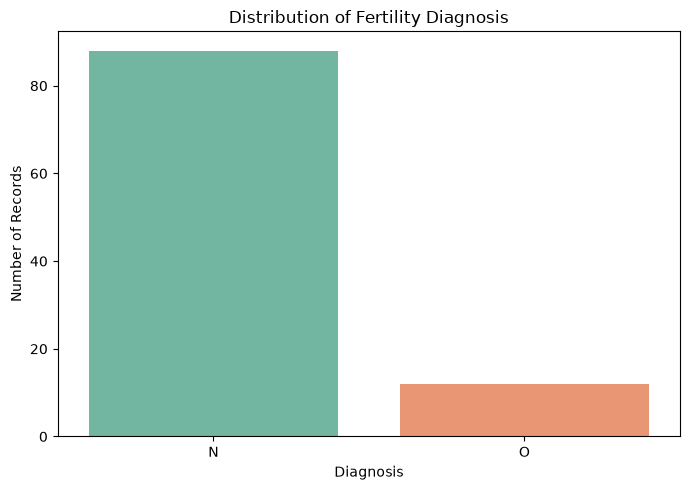

In [12]:
# Visualize diagnosis distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target_column,
    hue=target_column,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Fertility Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

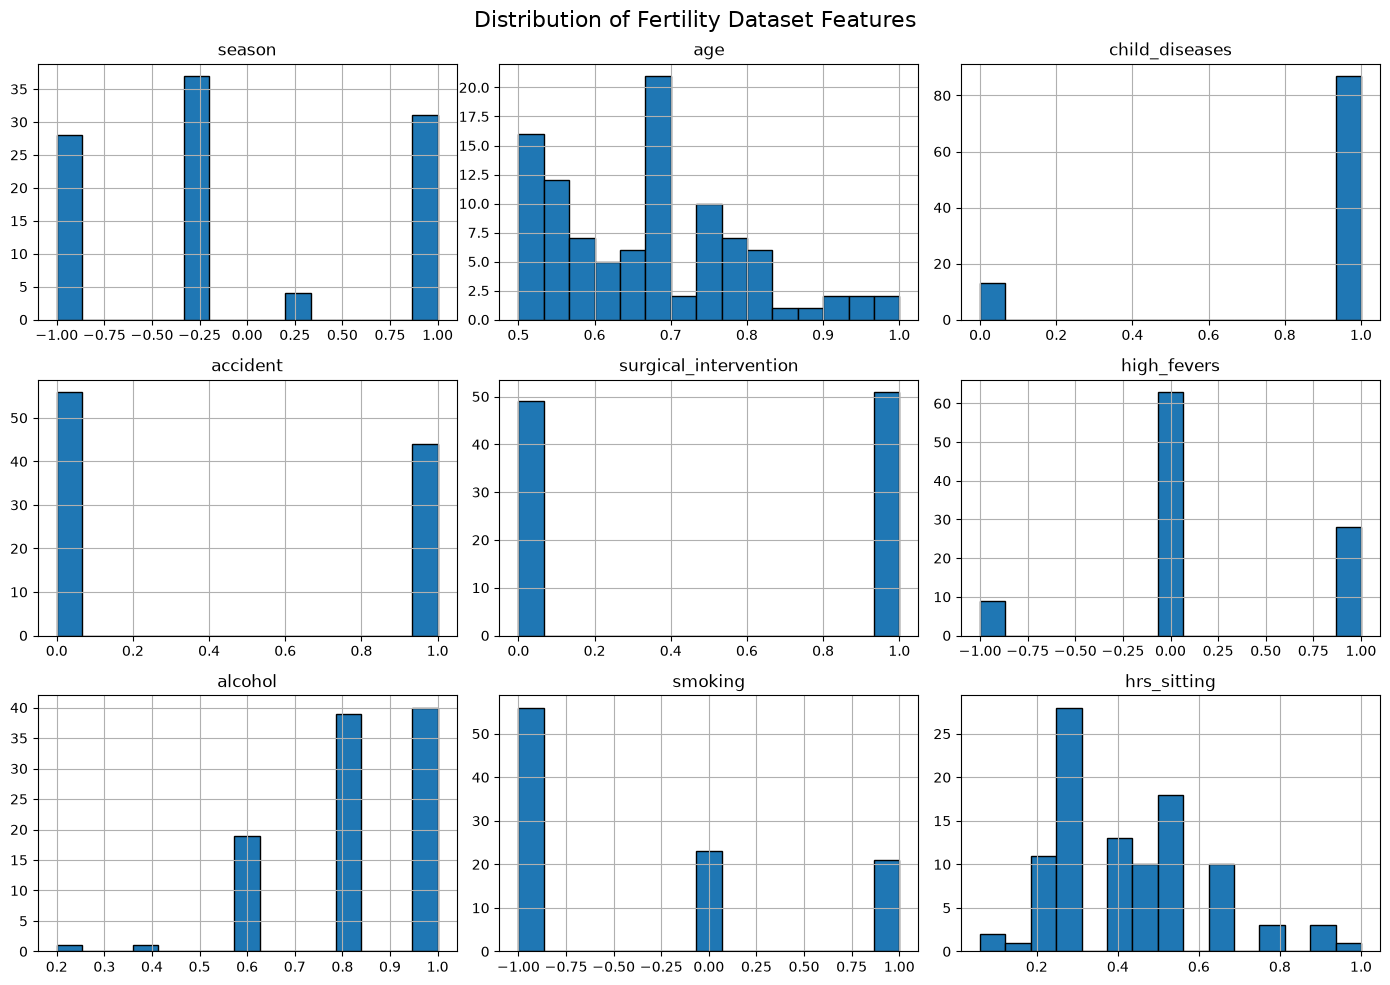

In [13]:
# Histograms of input features

X.hist(
    figsize=(14, 10),
    bins=15,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Fertility Dataset Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

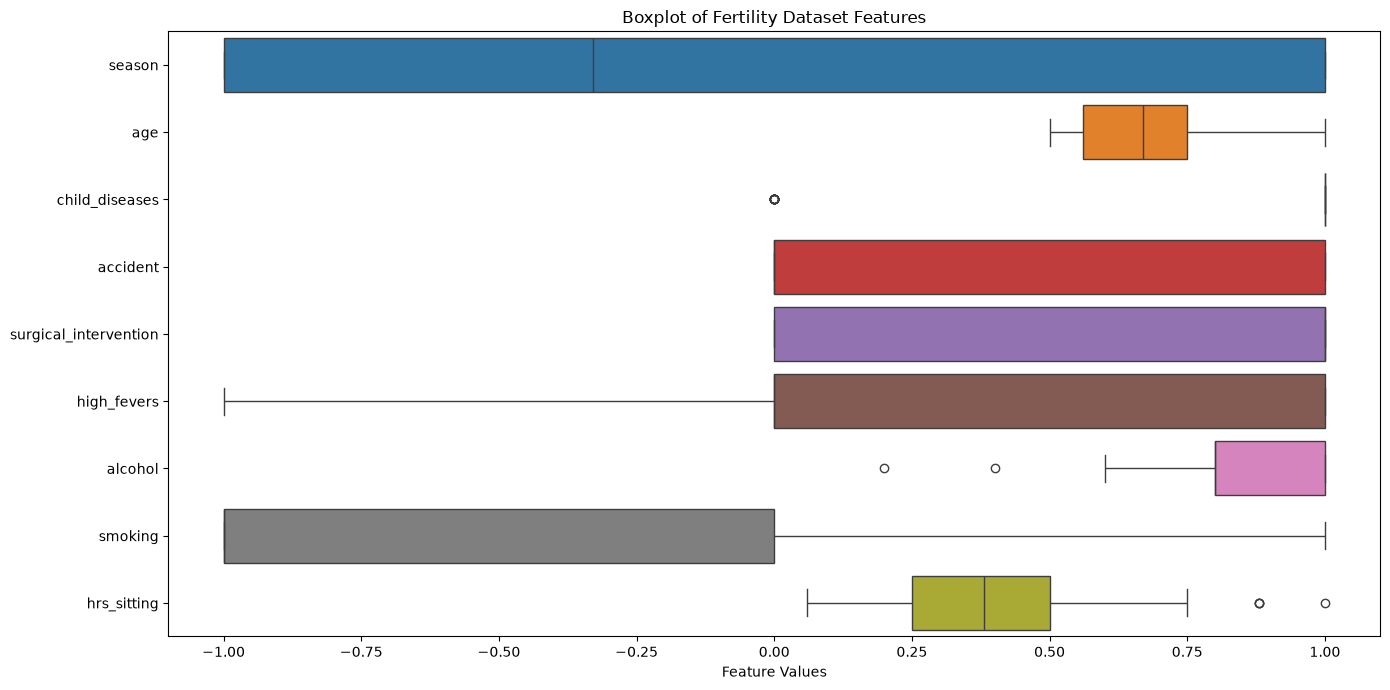

In [14]:
# Boxplots of input features

plt.figure(figsize=(14, 7))

sns.boxplot(data=X, orient="h")

plt.title("Boxplot of Fertility Dataset Features")
plt.xlabel("Feature Values")

plt.tight_layout()
plt.show()

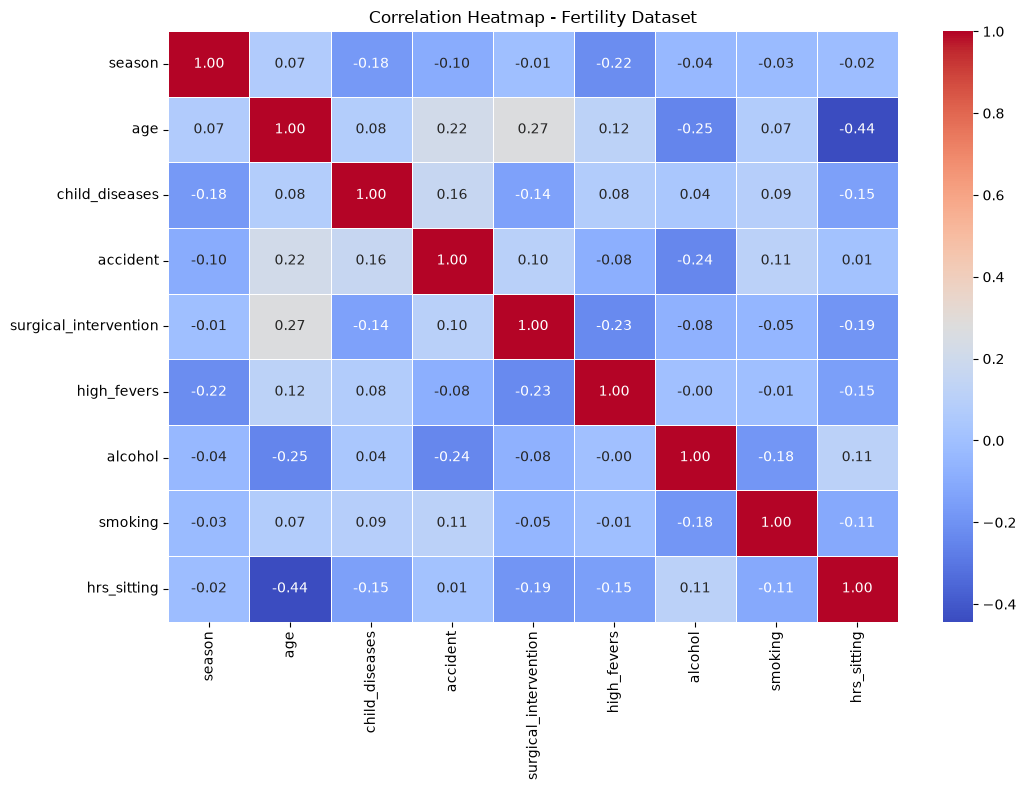

In [15]:
# Calculate correlation matrix

correlation = X.corr()

# Plot heatmap

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Fertility Dataset")

plt.tight_layout()
plt.show()

In [16]:
print("========== FERTILITY DATASET EDA SUMMARY ==========")

print("Total Records:", df.shape[0])

print("Total Input Features:", X.shape[1])

print("Target Variable:", target_column)

print("Number of Classes:", df[target_column].nunique())

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Records:", df.duplicated().sum())

print("\nDiagnosis Distribution:")

print(df[target_column].value_counts())

========== FERTILITY DATASET EDA SUMMARY ==========
Total Records: 100
Total Input Features: 9
Target Variable: diagnosis
Number of Classes: 2
Missing Values: 0
Duplicate Records: 0

Diagnosis Distribution:
diagnosis
N    88
O    12
Name: count, dtype: int64


In [17]:
print("Missing values in the dataset:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nNumber of duplicate records:")
print(df.duplicated().sum())

print("\nExact diagnosis distribution:")
print(df["diagnosis"].value_counts())

Missing values in the dataset:
season                   0
age                      0
child_diseases           0
accident                 0
surgical_intervention    0
high_fevers              0
alcohol                  0
smoking                  0
hrs_sitting              0
diagnosis                0
dtype: int64

Total missing values:
0

Number of duplicate records:
0

Exact diagnosis distribution:
diagnosis
N    88
O    12
Name: count, dtype: int64


## EDA Observations

1. The Fertility dataset contains 100 records and 9 input features.
2. The target variable is diagnosis, with two classes: Normal (N) and Altered (O).
3. The dataset contains no missing values.
4. The target classes are imbalanced, with more Normal records than Altered records.
5. The boxplot shows some potential outliers, which will not be removed without further investigation.
6. Most input features have weak correlations with one another.
7. The strongest visible feature correlation is between age and hours of sitting.

In [18]:
# Separate input features and target variable

X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Input features shape: (100, 9)
Target shape: (100,)

Target classes:
diagnosis
N    88
O    12
Name: count, dtype: int64


In [19]:
# Encode target labels

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Original classes:", label_encoder.classes_)
print("Encoded classes:", label_encoder.transform(label_encoder.classes_))

Original classes: ['N' 'O']
Encoded classes: [0 1]


In [20]:
# Split dataset into 70% training and 30% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting target distribution:")
print(pd.Series(y_test).value_counts())

Training features: (70, 9)
Testing features: (30, 9)

Training target distribution:
0    62
1     8
Name: count, dtype: int64

Testing target distribution:
0    26
1     4
Name: count, dtype: int64


In [21]:
# Apply feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data shape: (70, 9)
Scaled testing data shape: (30, 9)


In [22]:
# Import classification models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),

    "Support Vector Machine": SVC(
        class_weight="balanced"
    )
}

print("Four classification models are ready.")

Four classification models are ready.


In [23]:
# Train models and calculate evaluation metrics

results = []

for name, model in models.items():

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predict test data
    y_pred = model.predict(X_test_scaled)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=label_encoder.classes_,
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

           N       0.84      0.62      0.71        26
           O       0.09      0.25      0.13         4

    accuracy                           0.57        30
   macro avg       0.47      0.43      0.42        30
weighted avg       0.74      0.57      0.63        30


Decision Tree
              precision    recall  f1-score   support

           N       0.83      0.73      0.78        26
           O       0.00      0.00      0.00         4

    accuracy                           0.63        30
   macro avg       0.41      0.37      0.39        30
weighted avg       0.72      0.63      0.67        30


Random Forest
              precision    recall  f1-score   support

           N       0.85      0.88      0.87        26
           O       0.00      0.00      0.00         4

    accuracy                           0.77        30
   macro avg       0.43      0.44      0.43        30
weighted avg       0.74

In [24]:
# Create model comparison table

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,56.67%,46.65%,43.27%,42.22%
1,Decision Tree,63.33%,41.30%,36.54%,38.78%
2,Random Forest,76.67%,42.59%,44.23%,43.40%
3,Support Vector Machine,73.33%,52.08%,52.88%,52.00%


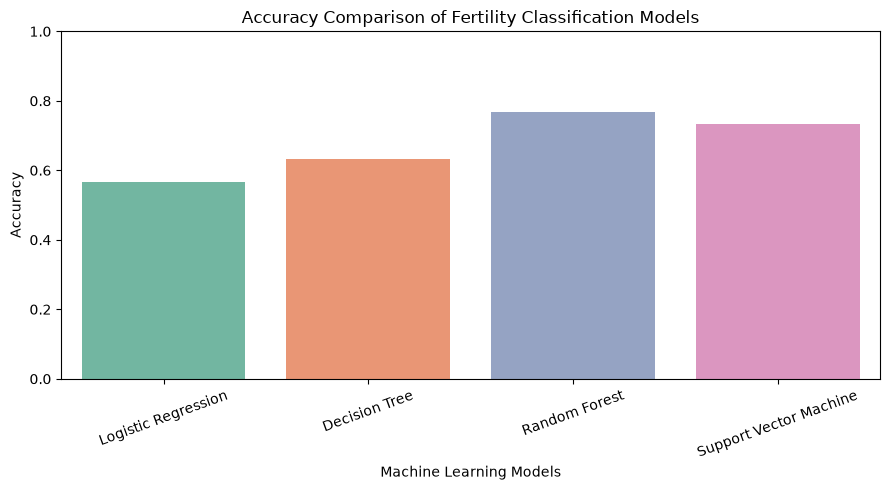

In [25]:
# Compare accuracy of all models

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Accuracy Comparison of Fertility Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

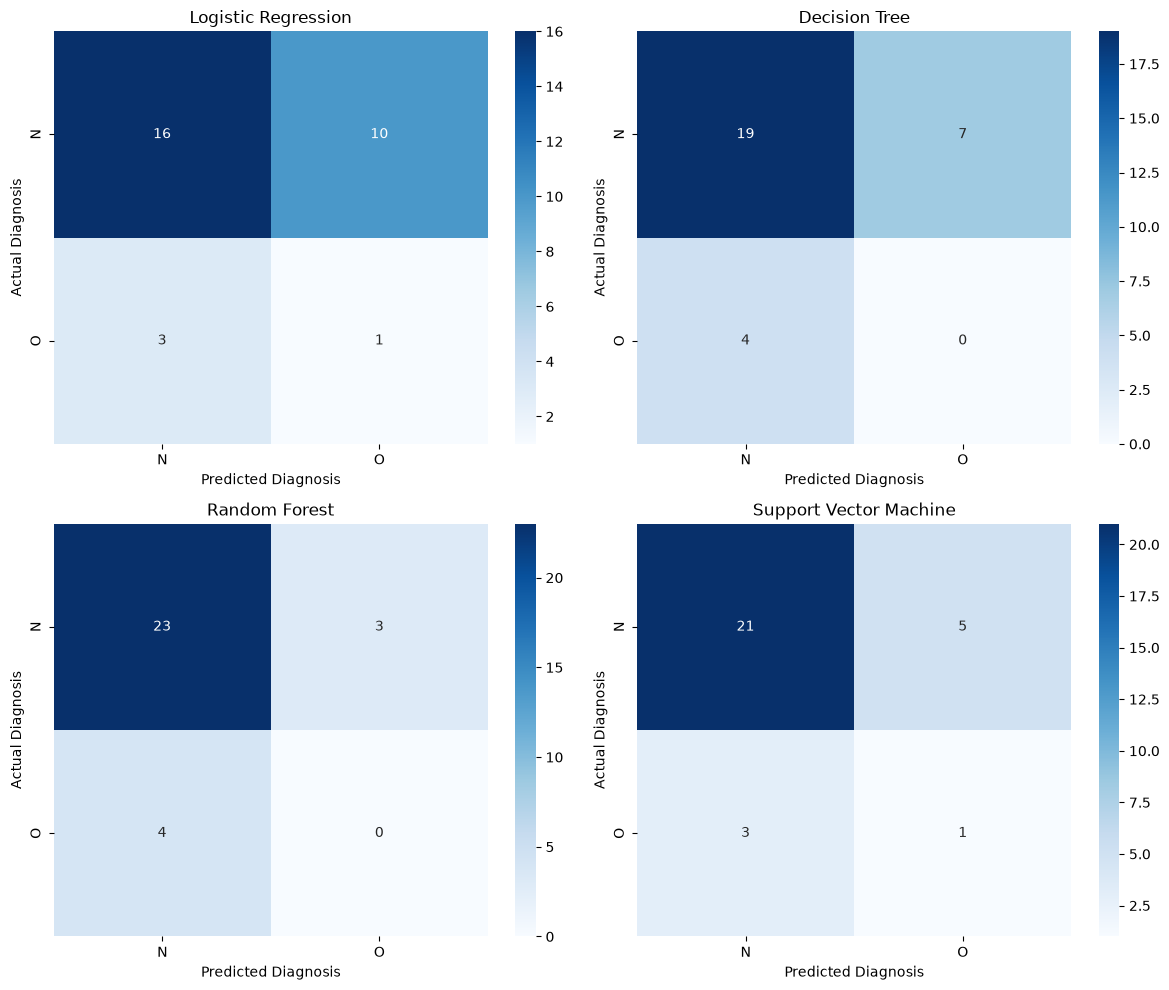

In [26]:
# Generate confusion matrices for all models

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Diagnosis")
    ax.set_ylabel("Actual Diagnosis")

plt.tight_layout()
plt.show()

In [27]:
# Save model comparison results

results_df.to_csv(
    "../results/fertility_model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


# Conclusion

The UCI Fertility dataset was successfully analyzed using Exploratory Data Analysis (EDA), data preprocessing and machine learning classification techniques.

The dataset contains 100 records, 9 input features and a binary target variable named Diagnosis. The dataset did not contain missing values. The target classes were imbalanced, with the Normal class having significantly more records than the Altered class.

The dataset was divided into 70% training data and 30% testing data. Feature scaling was performed using StandardScaler.

Four classification algorithms were implemented:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)

Among the four models, Random Forest achieved the highest accuracy of 76.67%. However, it failed to identify the Altered class.

Support Vector Machine achieved the highest macro F1-score of 52.00% and macro recall of 52.88%, making it the better-performing model when considering both target classes.

The experiment demonstrates the importance of evaluating multiple classification metrics, particularly when working with imbalanced datasets.

Since the dataset contains only 100 records and the test set contains just 30 records, the results may vary considerably with a different train-test split. Therefore, further evaluation using stratified cross-validation would be useful.

This experiment is intended for academic machine learning purposes and should not be considered a clinical fertility diagnosis.